# Practical 7 - Regression Analysis and ANOVA
Dataset: Diabetes progression (442 patients)
The regression and ANOVA tables are computed from first principles with NumPy and SciPy
(so no extra library is needed) and cross-checked against SciPy's own routines.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
def find_data(name):
    """Look for the CSV in the usual places; in Colab, ask for an upload if it is missing."""
    folders = (HERE.parent / "Datasets", HERE / "Datasets", HERE, Path.cwd(),
               Path("/content"), Path("/content/Datasets"), Path("/content/drive/MyDrive"))
    for folder in folders:
        if (folder / name).exists():
            return folder
    try:
        from google.colab import files
        print(f"{name} not found - please choose it in the upload dialog (it is in the Datasets folder).")
        files.upload()
        return Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Could not find {name}. Put it in a 'Datasets' folder next to this script.")

DATA = find_data("diabetes_progression.csv")
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

ALPHA = 0.05
df = pd.read_csv(DATA / "diabetes_progression.csv")
print("Patients:", len(df), "| outcome variable: progression (mean %.1f)" % df["progression"].mean())

Patients: 442 | outcome variable: progression (mean 152.1)


## Tools: an OLS routine and a one-way ANOVA routine

In [2]:
def ols(X, y, names):
    """Ordinary least squares with an intercept. Returns a dict of results."""
    X = np.column_stack([np.ones(len(X)), X])
    n, k = X.shape
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    sse = resid @ resid
    sst = ((y - y.mean()) ** 2).sum()
    sigma2 = sse / (n - k)
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), n - k)
    r2 = 1 - sse / sst
    f = ((sst - sse) / (k - 1)) / sigma2
    return {"table": pd.DataFrame({"coef": beta, "std err": se, "t": t, "P>|t|": p},
                                  index=["Intercept"] + names),
            "n": n, "r2": r2, "adj_r2": 1 - (1 - r2) * (n - 1) / (n - k),
            "F": f, "F_p": stats.f.sf(f, k - 1, n - k)}

def show(res, title):
    print(title)
    shown = res["table"].round(4).astype(object)
    shown["P>|t|"] = res["table"]["P>|t|"].map(lambda v: f"{v:.2e}")
    print(shown.to_string())
    print(f"n = {res['n']}   R-squared = {res['r2']:.4f}   Adj. R-squared = {res['adj_r2']:.4f}")
    print(f"F = {res['F']:.4f}   Prob(F) = {res['F_p']:.3e}")

def anova_oneway(frame, value, group):
    parts = [g[value].to_numpy() for _, g in frame.groupby(group, observed=True)]
    grand = frame[value].mean()
    ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in parts)
    ss_w = sum(((g - g.mean()) ** 2).sum() for g in parts)
    df_b, df_w = len(parts) - 1, len(frame) - len(parts)
    f = (ss_b / df_b) / (ss_w / df_w)
    return pd.DataFrame({"df": [df_b, df_w], "sum_sq": [ss_b, ss_w],
                         "mean_sq": [ss_b / df_b, ss_w / df_w],
                         "F": [f, np.nan], "p": [stats.f.sf(f, df_b, df_w), np.nan]},
                        index=[group, "Residual"])

## Q1. Does blood pressure level affect disease progression?
Patients are labelled "high" if their blood pressure is above the median.

In [3]:
df["bp_level"] = np.where(df["bp"] > df["bp"].median(), "high", "normal")
dummy = (df["bp_level"] == "high").astype(float).to_numpy().reshape(-1, 1)

q1 = ols(dummy, df["progression"].to_numpy(), ["bp_level[high]"])
show(q1, "OLS: progression ~ bp_level")
print("\nH0: mean progression is the same for both blood-pressure levels")
p = q1["table"].loc["bp_level[high]", "P>|t|"]
print("Decision:", "REJECT H0" if p < ALPHA else "FAIL TO REJECT H0")
print(f"High-BP patients progress by {q1['table'].loc['bp_level[high]', 'coef']:.2f} points more on average")

OLS: progression ~ bp_level
                    coef std err        t     P>|t|
Intercept       126.8841  4.7436  26.7486  2.72e-94
bp_level[high]   53.3982  6.8983   7.7407  6.85e-14
n = 442   R-squared = 0.1199   Adj. R-squared = 0.1179
F = 59.9189   Prob(F) = 6.845e-14

H0: mean progression is the same for both blood-pressure levels
Decision: REJECT H0
High-BP patients progress by 53.40 points more on average


## Q2. One-way ANOVA: does BMI differ between age groups?

           count    mean    std
age_group                      
under 40     122  25.385  4.915
40-55        177  26.346  4.289
over 55      143  27.258  3.952

            df       sum_sq     mean_sq         F         p
age_group    2   231.169956  115.584978  6.057232  0.002541
Residual   439  8377.061016   19.082144       NaN       NaN

SciPy cross-check: F = 6.0572, p = 2.541e-03
Decision: REJECT H0 - BMI differs across age groups


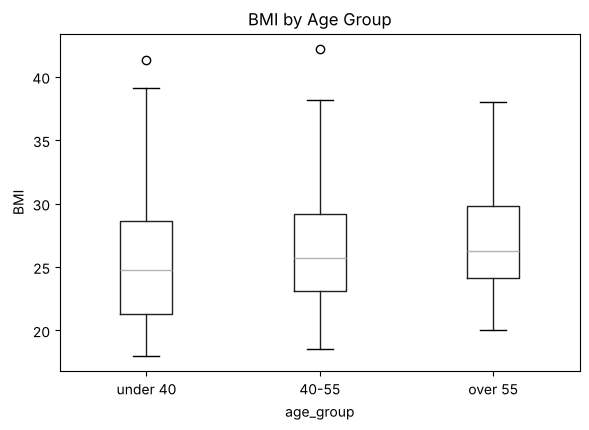

In [4]:
df["age_group"] = pd.cut(df["age"], bins=[0, 40, 55, 120], labels=["under 40", "40-55", "over 55"])
print(df.groupby("age_group", observed=True)["bmi"].agg(["count", "mean", "std"]).round(3).to_string())

table = anova_oneway(df, "bmi", "age_group")
print()
print(table.round(6).to_string())

check = stats.f_oneway(*[g["bmi"] for _, g in df.groupby("age_group", observed=True)])
print(f"\nSciPy cross-check: F = {check.statistic:.4f}, p = {check.pvalue:.3e}")
print("Decision:", "REJECT H0 - BMI differs across age groups" if table.loc["age_group", "p"] < ALPHA
      else "FAIL TO REJECT H0 - no evidence BMI differs across age groups")

df.boxplot(column="bmi", by="age_group", grid=False, figsize=(6.5, 4.5))
plt.suptitle("")
plt.title("BMI by Age Group")
plt.ylabel("BMI")
plt.savefig(FIG / "bmi_by_age_group.png", dpi=120, bbox_inches="tight")
plt.show()

## Q3. Simple linear regression: progression ~ BMI

OLS: progression ~ bmi
               coef  std err        t     P>|t|
Intercept -117.7734  18.0189  -6.5361  1.75e-10
bmi         10.2331   0.6738  15.1873  3.47e-42
n = 442   R-squared = 0.3439   Adj. R-squared = 0.3424
F = 230.6538   Prob(F) = 3.466e-42

SciPy cross-check: slope = 10.2331, intercept = -117.7734, r = 0.5865
Each extra BMI point is associated with 10.23 more progression points.


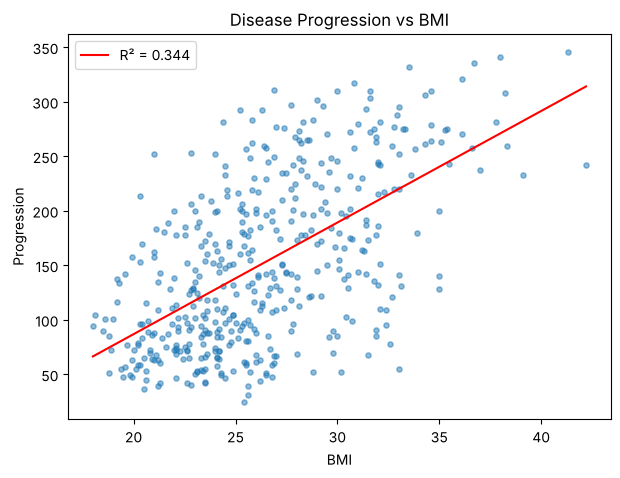

In [5]:
q3 = ols(df[["bmi"]].to_numpy(), df["progression"].to_numpy(), ["bmi"])
show(q3, "OLS: progression ~ bmi")

lin = stats.linregress(df["bmi"], df["progression"])
print(f"\nSciPy cross-check: slope = {lin.slope:.4f}, intercept = {lin.intercept:.4f}, r = {lin.rvalue:.4f}")
print(f"Each extra BMI point is associated with {lin.slope:.2f} more progression points.")

plt.figure(figsize=(7, 5))
plt.scatter(df["bmi"], df["progression"], s=14, alpha=0.5)
xs = np.array([df["bmi"].min(), df["bmi"].max()])
plt.plot(xs, lin.intercept + lin.slope * xs, color="red", label=f"R² = {q3['r2']:.3f}")
plt.title("Disease Progression vs BMI")
plt.xlabel("BMI")
plt.ylabel("Progression")
plt.legend()
plt.savefig(FIG / "progression_vs_bmi.png", dpi=120, bbox_inches="tight")
plt.show()

## Interpretation
R-squared is the share of the variation in progression explained by the predictor.
Both models leave most of it unexplained, so other measurements also matter.

In [6]:
print(f"Q1 model explains {q1['r2']:.1%} of the variation in progression")
print(f"Q3 model explains {q3['r2']:.1%} of the variation in progression")

Q1 model explains 12.0% of the variation in progression
Q3 model explains 34.4% of the variation in progression
